# Exercise 3: Deep Q-Networks (DQN)

In this exercise, we will implement a Deep Q-Network for `CartPole-v1` in two ways:
1. **Manually with PyTorch:** To understand the inner workings (Neural Networks, Experience Replay, Target Networks).
2. **With Stable-Baselines3 (SB3):** To see how professionals accelerate development using high-level libraries.

# Imports & Setup

In [1]:
import logging
import sys
import os
import gymnasium as gym
import matplotlib.pyplot as plt
import torch

# Configure logging
logging.basicConfig(level=logging.INFO, format='%(message)s', force=True)
sys.path.append(os.path.abspath('..'))

from src.exercise_3.pytorch_dqn import DQN
from src.exercise_3.pytorch_training import train_pytorch_dqn, device
from src.exercise_3.visualization import display_pytorch_agent
from src.exercise_3.sb3_dqn import train_sb3_dqn
from src.exercise_3.visualization import display_sb3_agent

## Part 1: Manual PyTorch DQN

First, we set up the environment and initialize our custom Neural Network (`DQN`) and our memory bank (`ReplayBuffer`).
We need *two* networks: a `policy_net` (which makes decisions) and a `target_net` (which provides stable goals during training).

In [2]:
env_id = "CartPole-v1"
env = gym.make(env_id)

# Get number of actions and observations to size the neural network correctly
n_actions = env.action_space.n
n_observations = env.observation_space.shape[0]

policy_net = DQN(n_observations, n_actions).to(device)
target_net = DQN(n_observations, n_actions).to(device)
target_net.load_state_dict(policy_net.state_dict())

print("Neural Network Architecture:\n", policy_net)

Neural Network Architecture:
 DQN(
  (layer1): Linear(in_features=4, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=128, bias=True)
  (layer3): Linear(in_features=128, out_features=2, bias=True)
)


### Training the Custom PyTorch Network

Now we run the training loop. Open `src/exercise_3/pytorch_training.py` to see the `optimize_model()` function, which contains the core math.

Training Custom PyTorch DQN on mps...
/Users/asmaaliouche/OC/7. Reinforcement Learning/src/exercise_3/pytorch_training.py:29: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:255.)
  state_batch = torch.tensor(batch_state, dtype=torch.float32, device=device)
Episode 50/300 - Reward: 106.0 (Epsilon: 0.51)
Episode 100/300 - Reward: 169.0 (Epsilon: 0.06)
Episode 150/300 - Reward: 225.0 (Epsilon: 0.05)
Episode 200/300 - Reward: 253.0 (Epsilon: 0.05)
Episode 250/300 - Reward: 85.0 (Epsilon: 0.05)
Episode 300/300 - Reward: 500.0 (Epsilon: 0.05)
Training complete.


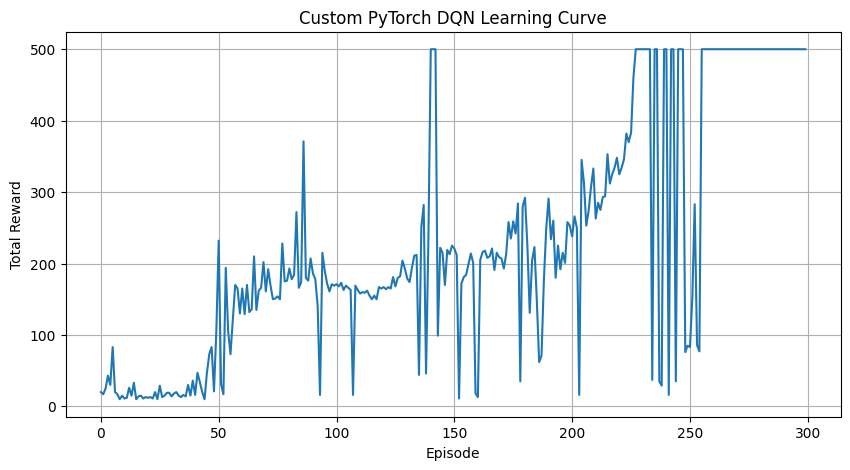

In [3]:
# Train for 300 episodes 
rewards = train_pytorch_dqn(env, policy_net, target_net, num_episodes=300)

# Plot the learning curve
plt.figure(figsize=(10, 5))
plt.plot(rewards)
plt.title('Custom PyTorch DQN Learning Curve')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.grid(True)
plt.show()

### Visualizing the Custom PyTorch Agent

Let's see how well our manually built neural network performs balancing the pole!

In [4]:
display_pytorch_agent(env_id, policy_net, max_steps=500)

Visualizing PyTorch agent in 'CartPole-v1'...
Episode ended after 500 steps. Total Reward: 500.00
Animation.save using <class 'matplotlib.animation.HTMLWriter'>


## Part 2: Stable-Baselines3 (SB3)

Writing a DQN from scratch is great for learning, but it takes hundreds of lines of code. 
Now, let's use the Stable-Baselines3 library to do the exact same thing in just a few lines.

In [5]:
# This will train the model, evaluate it over 100 episodes, and save it as a .zip file.
model = train_sb3_dqn(env_id="CartPole-v1", total_timesteps=25000)

--- Training Stable-Baselines3 DQN on CartPole-v1 ---
Learning for 25000 timesteps...
Evaluating the trained model over 100 episodes...
/Users/asmaaliouche/OC/7. Reinforcement Learning/.venv/lib/python3.10/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(
Mean reward: 148.88 +/- 19.93
Model saved to dqn_cartpole.zip


### Visualizing the SB3 Agent

Let's watch the professionally implemented SB3 agent play.

In [6]:
display_sb3_agent(env_id, model, max_steps=500)

Visualizing Stable-Baselines3 agent in 'CartPole-v1'...
Episode ended after 183 steps. Total Reward: 183.00
Animation.save using <class 'matplotlib.animation.HTMLWriter'>
